In [19]:
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
import random

In [2]:
from convokit import Corpus, download
corpus = Corpus(filename=download("conversations-gone-awry-corpus"))
corpus.print_summary_stats()

Dataset already exists at /Users/caseygilbert/.convokit/saved-corpora/conversations-gone-awry-corpus
Number of Speakers: 8069
Number of Utterances: 30021
Number of Conversations: 4188


In [7]:

# Get convo df
convo_db = corpus.get_attribute_table("conversation", ["conversation_has_personal_attack", "page_title", "page_id", "pair_id", "conversation_has_personal_attack", "verified", "pair_verified", "annotation_year"])
convo_db.reset_index(inplace=True)

# Get utter df
utter_df = corpus.get_utterances_dataframe()

# Merge them to get speakers
full_utter = pd.merge(utter_df, convo_db, left_on='conversation_id', right_on='id', how='outer')

# And add speakers column to convo_db
convo_db['speakers'] = [[] for _ in range(len(convo_db))]

# Now loop through and give speakers to conversation db
for index, row in full_utter.iterrows():
    conversation_id = row["conversation_id"]
    if not row["speaker"] in convo_db.loc[convo_db['id'] == conversation_id]["speakers"].iloc[0]:
        convo_db.loc[convo_db['id'] == conversation_id]["speakers"].iloc[0].append(row["speaker"])

# Now get speakers df
speakers = corpus.get_speakers_dataframe()

In [11]:
# Build our bipartite network

sample_graph = nx.Graph()
speaker_list = []
conversation_list = []

for index in speakers.iterrows():
    speaker_list.append(index[0])
    
sample_graph.add_nodes_from(speaker_list, bipartite=0, node_type="speaker")

for row, index in convo_db.iterrows():
    conversation_list.append(index["id"])
    sample_graph.add_node(index["id"], bipartite=1, node_type="conversation", conversation_has_personal_attack=index["conversation_has_personal_attack"], page_title=index["page_title"], page_id=index["page_id"], pair_id=index["pair_id"], verified=index["verified"], pair_verified=index["pair_verified"], annotation_year=index["annotation_year"])
    for speaker in index["speakers"]:
        sample_graph.add_edge(speaker, index["id"], is_personal_attack=index["conversation_has_personal_attack"])


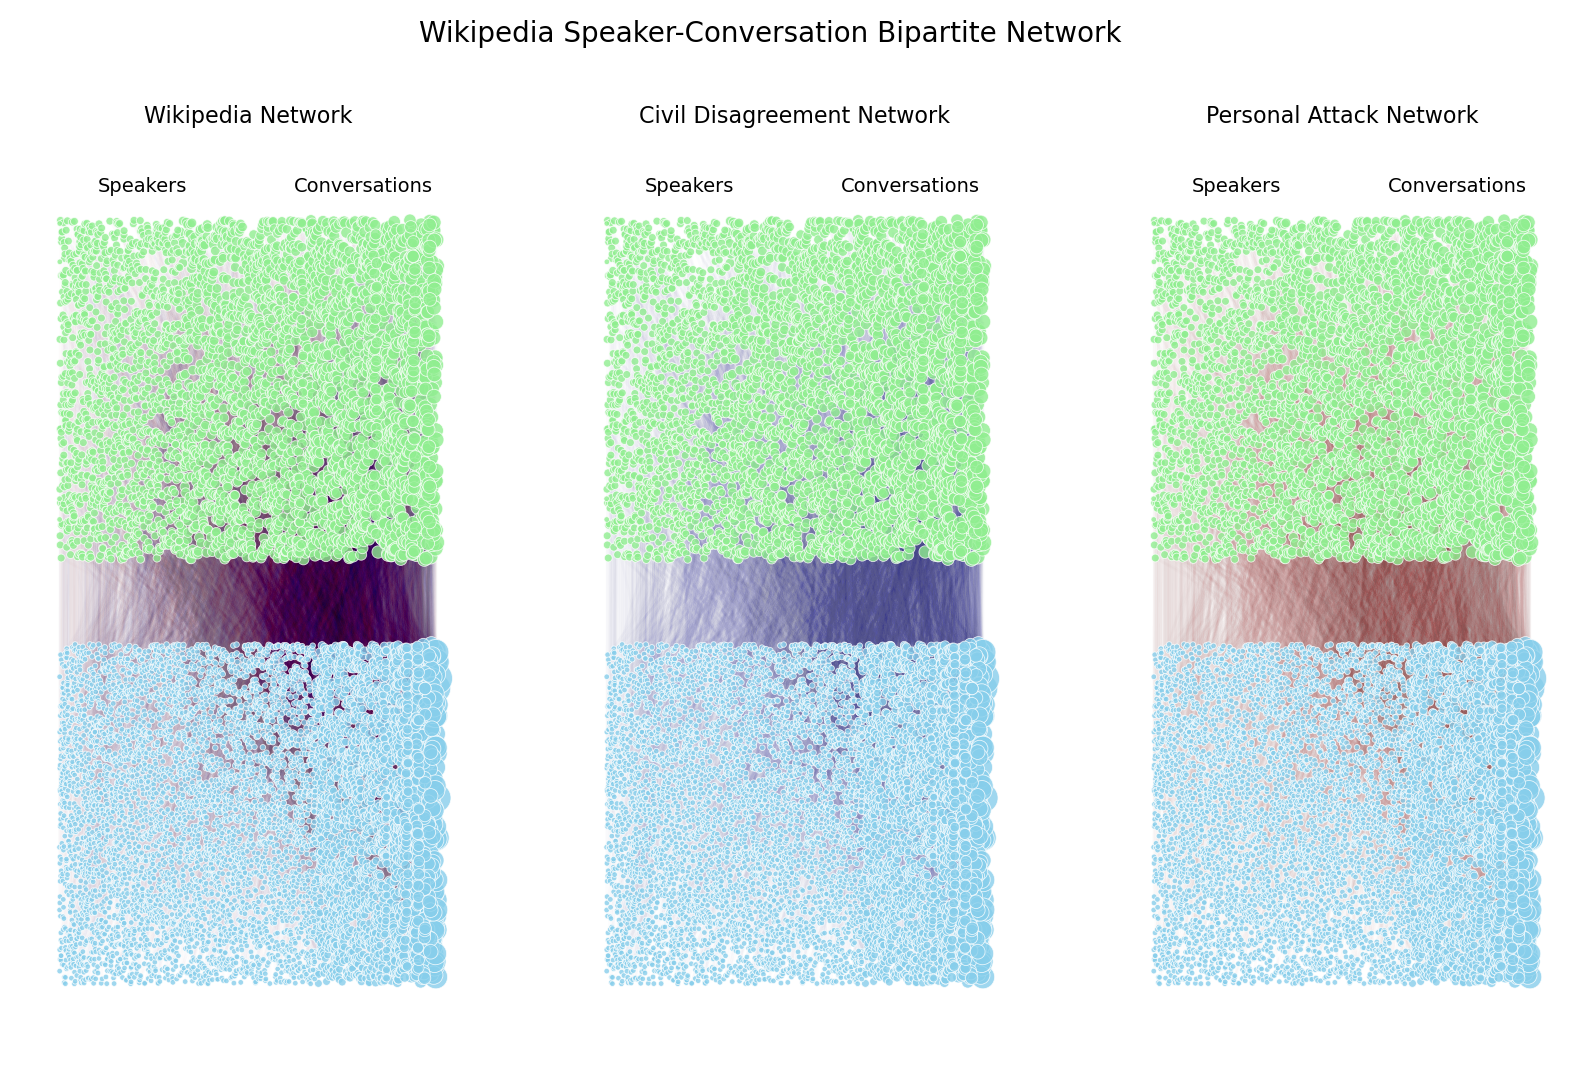

In [111]:
# Visualize our Network
fig, ax = plt.subplots(1,3,figsize=(10,6),dpi=200)

# sort by size
speaker_list_sorted = sorted(speaker_list, key=lambda n: sample_graph.degree(n))
conversation_list_sorted = sorted(conversation_list, key=lambda n: sample_graph.degree(n))


#pos = nx.bipartite_layout(sample_graph, speaker_list_sorted, align="horizontal")

# add jitter
jitter_amount = .4

pos = {}
for i, node in enumerate(speaker_list_sorted):
    jittered_pos = random.uniform(-jitter_amount, jitter_amount)
    pos[node] = (i, 0 + jittered_pos)   # x=0 column
for i, node in enumerate(conversation_list_sorted):
    # i of convo = x of speaker 
    updated_i = round((i * len(speaker_list_sorted))/len(conversation_list_sorted))
    jittered_pos = random.uniform(-jitter_amount, jitter_amount)
    pos[node] = (updated_i, 1 + jittered_pos)   # x=1 column

deg_dist = list(dict(sample_graph.degree()).values())

# # add jitter
# jitter_amount = .4
# for node in pos:
#     pos[node][1] += random.uniform(-jitter_amount, jitter_amount)

# Label box properties
box_properties = dict(
    boxstyle='square',
    facecolor='white',
    edgecolor='white',     
    alpha=0,
    linewidth=.5             
)


# Left plot
# Clarify edge colors
edge_colors = [
    "darkblue" if data["is_personal_attack"] == False else "darkred"
    for u, v, data in sample_graph.edges(data=True)
]

# Labels 
# Speakers Text 
plt.text(
    0.17, .96, 
    "Speakers", 
    transform=ax[0].transAxes, 
    fontsize=7,
    verticalalignment='top', 
    bbox=box_properties
)

# Conversations Text 
plt.text(
    .6, .96, 
    "Conversations", 
    transform=ax[0].transAxes, 
    fontsize=7,
    verticalalignment='top', 
    bbox=box_properties
)

nx.draw_networkx_edges(sample_graph, pos, width=1, edge_color=edge_colors, ax=ax[0], alpha=0.008)
nx.draw_networkx_nodes(sample_graph, pos, node_size=[4*x for x in deg_dist], node_color=["skyblue"] * len(speaker_list) + ["lightgreen"] * len(conversation_list), alpha=0.8,
                       edgecolors='w', linewidths=0.3, ax=ax[0])

ax[0].set_title("Wikipedia Network",  fontsize=8)

# Center plot
# Labels 
# Speakers Text 
plt.text(
    0.17, .96, 
    "Speakers", 
    transform=ax[1].transAxes, 
    fontsize=7,
    verticalalignment='top', 
    bbox=box_properties
)

# Conversations Text 
plt.text(
    .6, .96, 
    "Conversations", 
    transform=ax[1].transAxes, 
    fontsize=7,
    verticalalignment='top', 
    bbox=box_properties
)

# Clarify edge colors
edge_colors_v2 = [
    "white" if data["is_personal_attack"] == True else "darkblue"
    for u, v, data in sample_graph.edges(data=True)
]

nx.draw_networkx_edges(sample_graph, pos, width=1, edge_color=edge_colors_v2, ax=ax[1], alpha=0.01)
nx.draw_networkx_nodes(sample_graph, pos, node_size=[4*x for x in deg_dist], node_color=["skyblue"] * len(speaker_list) + ["lightgreen"] * len(conversation_list), alpha=0.8,
                       edgecolors='w', linewidths=0.3, ax=ax[1])

ax[1].set_title("Civil Disagreement Network", fontsize=8)

# Right plot
# Labels 
# Speakers Text 
plt.text(
    0.17, .96, 
    "Speakers", 
    transform=ax[2].transAxes, 
    fontsize=7,
    verticalalignment='top', 
    bbox=box_properties
)

# Conversations Text 
plt.text(
    .6, .96, 
    "Conversations", 
    transform=ax[2].transAxes, 
    fontsize=7,
    verticalalignment='top', 
    bbox=box_properties
)

# Clarify edge colors
edge_colors_v3 = [
    "white" if data["is_personal_attack"] == False else "darkred"
    for u, v, data in sample_graph.edges(data=True)
]

nx.draw_networkx_edges(sample_graph, pos, width=1, edge_color=edge_colors_v3, ax=ax[2], alpha=0.01)
nx.draw_networkx_nodes(sample_graph, pos, node_size=[4*x for x in deg_dist], node_color=["skyblue"] * len(speaker_list) + ["lightgreen"] * len(conversation_list), alpha=0.8,
                       edgecolors='w', linewidths=0.3, ax=ax[2])

ax[2].set_title("Personal Attack Network", fontsize=8)


ax[0].set_frame_on(False)
ax[1].set_frame_on(False)
ax[2].set_frame_on(False)
plt.box(False)
plt.suptitle("Wikipedia Speaker-Conversation Bipartite Network", fontsize=10)
plt.show()

In [7]:
speakers_nodes = {n for n, d in sample_graph.nodes(data=True) if d["bipartite"] == 0}
conversations_nodes = {n for n, d in sample_graph.nodes(data=True) if d["bipartite"] == 1}

projected_graph = nx.bipartite.projected_graph(sample_graph, speakers_nodes)

print(f"Node count: {sample_graph.number_of_nodes()}")
print(f"Edge count: {sample_graph.number_of_edges()}")
print("\n  ")
print(f"Node count: {projected_graph.number_of_nodes()}")
print(f"Edge count: {projected_graph.number_of_edges()}")

Node count: 12257
Edge count: 13681

  
Node count: 8069
Edge count: 17407


In [8]:
type(convo_db["conversation_has_personal_attack"][0])

numpy.bool

In [14]:
attack_nodes = [n for n, d in sample_graph.nodes(data=True) if d.get("conversation_has_personal_attack") == True]

non_attack_nodes = [n for n, d in sample_graph.nodes(data=True) if d.get("conversation_has_personal_attack") == True and d.get("node_type") == "conversation"]
convo_nodes = [n for n, d in sample_graph.nodes(data=True) if d.get("node_type") == "conversation"]
print(f"Convo nodes: {len(convo_nodes)}")
print(f"Attack nodes: {len(attack_nodes)}")
print(f"Not nodes: {len(non_attack_nodes)}")


Convo nodes: 4188
Attack nodes: 2094
Not nodes: 2094


In [2]:
attack_nodes = [n for n, d in sample_graph.nodes(data=True) if d.get("conversation_has_personal_attack") == True]
projected_G = nx.Graph()

for obj in conversations_nodes:
    # Get the specific characteristic of this opposite node
    characteristic = sample_graph.nodes[obj].get("conversation_has_personal_attack", "unknown")

    # Find all target nodes (Users) connected to this opposite node
    neighbors = list(sample_graph.neighbors(obj))

    # Connect all pairs of neighbors sharing this node
    for i in range(len(neighbors)):
        for j in range(i + 1, len(neighbors)):
            u, v = neighbors[i], neighbors[j]

            if not projected_G.has_node(u):
                projected_G.add_node(u)

            # If the edge already exists, update it; otherwise, create it
            if projected_G.has_edge(u, v):
                # Example: Append characteristic to a list of shared traits
                projected_G[u][v]["shared_via"].append(characteristic)
            else:
                # Initialize the edge with the characteristic attribute
                projected_G.add_edge(u, v, shared_via=[characteristic])


NameError: name 'sample_graph' is not defined

In [84]:
nx.write_gexf(sample_graph, "constructive_convo.gexf", version="1.2draft")
nx.write_gexf(projected_graph, "constructive_convo_projected.gexf", version="1.2draft")